# 03 — Results: comparing the strategies

The same simulation on the test set (2 October 2017 – 3 February 2018, 125 days) with five strategies. The notebook reads the results of `python -m microgrid.evaluate`.

- **No battery**: PV covers the load, the rest goes to or comes from the grid.
- **Naive rule**: the battery charges when there is a solar surplus and discharges when there is a deficit. It uses neither forecasts nor prices.
- **Forecast + MILP**: the plan computed on the forecasts is executed to the letter; the grid absorbs the forecast error.
- **Forecast + MILP + correction**: we track the grid exchange the plan expected; the battery absorbs the forecast error for as long as it can. The correction rule was chosen on the validation period.
- **Perfect forecast + MILP**: the plan is computed on the actual values. It is the theoretical reference.

Tariff: we buy at the day-ahead price plus a 0.20 €/kWh surcharge, and sell at the day-ahead price.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from microgrid.config import load_config, resolve_path
from microgrid.evaluate import COMPARISON_FILE, DAILY_FILE, PARETO_FILE, SENSITIVITY_FILE, STRATEGIES
from microgrid.plotting import COLORS, STRATEGY_STYLES, apply_style, plot_comparison, plot_pareto, plot_sensitivity

apply_style()
config = load_config()
results_dir = resolve_path(config["paths"]["results"])
comparison = pd.read_csv(results_dir / COMPARISON_FILE, index_col="strategy")
daily = pd.read_csv(results_dir / DAILY_FILE, index_col="day", parse_dates=True)
front = pd.read_csv(results_dir / PARETO_FILE)
sweep = pd.read_csv(results_dir / SENSITIVITY_FILE)
with_battery = [name for name in STRATEGIES if name != "no_battery"]
print(f"{len(daily)} days, {len(comparison)} strategies")

125 days, 6 strategies


## 1. Cost and emissions

`saving captured` is the cost saving divided by that of the perfect forecast. The last row is a variant: like *Forecast + MILP + correction*, but with the naive load forecast in place of the model.

In [2]:
columns = {"description": "strategy", "cost_eur": "cost (€)", "emissions_kg": "emissions (kgCO₂)",
           "cost_saving_pct": "cost saving (%)", "emissions_saving_pct": "emission saving (%)",
           "saving_captured": "saving captured", "battery_cycles": "cycles",
           "soc_end_kwh": "final energy (kWh)", "residual_value_eur": "leftover energy value (€)"}
table = comparison[list(columns)].rename(columns=columns).set_index("strategy")
table.round({"cost (€)": 0, "emissions (kgCO₂)": 0, "cost saving (%)": 1, "emission saving (%)": 1,
             "saving captured": 2, "cycles": 1, "final energy (kWh)": 0, "leftover energy value (€)": 1})

,cost (€),emissions (kgCO₂),cost saving (%),emission saving (%),saving captured,cycles,final energy (kWh),leftover energy value (€)
strategy,,,,,,,,
No battery,6069.0,10496.0,0.0,0.0,0.00,0.0,100.0,0.0
Naive rule,4691.0,7878.0,22.7,24.9,0.94,44.5,20.0,-17.7
Forecast + MILP,5554.0,9527.0,8.5,9.2,0.35,65.6,100.0,-0.0
Forecast + MILP + correction,4842.0,8208.0,20.2,21.8,0.84,74.5,20.0,-17.7
Perfect forecast + MILP,4602.0,7802.0,24.2,25.7,1.00,76.6,100.0,-0.0
Naive load forecast + MILP + correction,4869.0,8249.0,19.8,21.4,0.82,72.0,27.0,-16.1


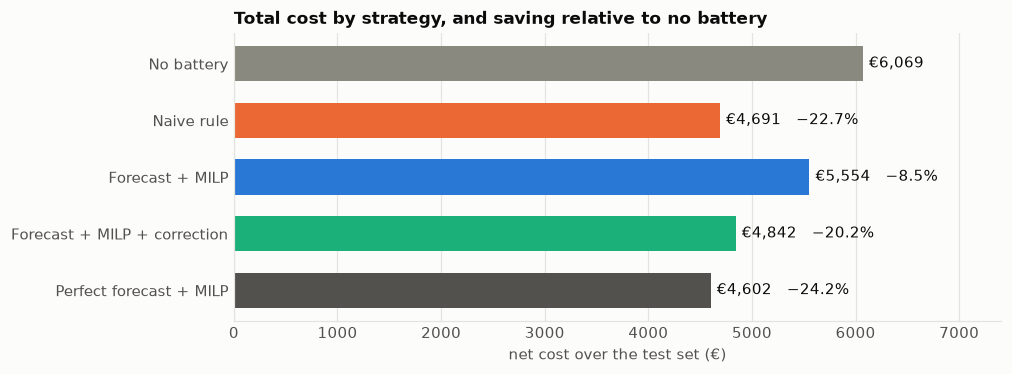

In [3]:
plot_comparison(comparison, STRATEGIES)
plt.show()

**What we see**

- **The naive rule beats the forecast + optimisation system.** It saves 22.7%, against 8.5% for the plan executed to the letter and 20.2% for the plan with correction. It captures 94% of the theoretical saving using neither forecasts nor prices.
- **Executing the plan to the letter is expensive.** Every kWh of forecast error lands on the grid: bought at about 0.23 €/kWh if it is missing, sold at about 0.03 €/kWh if it is spare. The battery does 66 cycles but leaves two thirds of the possible saving on the table.
- **The real-time correction recovers almost all of it**: from €5,554 to €4,842. It stays €152 above the naive rule.
- **There is little room for optimisation.** Between the naive rule and the perfect forecast there are €89 over 125 days (€107 counting leftover energy): under 2% of the no-battery cost. With a 0.20 €/kWh surcharge almost only self-consumption matters, and the naive rule is enough to maximise it.
- **Leftover energy.** The naive rule and the plan with correction end with the battery at its minimum (20 kWh), the MILP strategies without correction at 100 kWh: the 80 kWh difference is worth about €18. It does not change the ranking.
- **Variant with the naive load forecast.** Using the naive load forecast instead of the model costs €26 more: for this problem the two load forecasts are equivalent.
- Emissions follow cost: the less we buy, the less we emit.

## 2. Saving accumulated over time

Cumulative difference between the no-battery cost and the cost of each strategy.

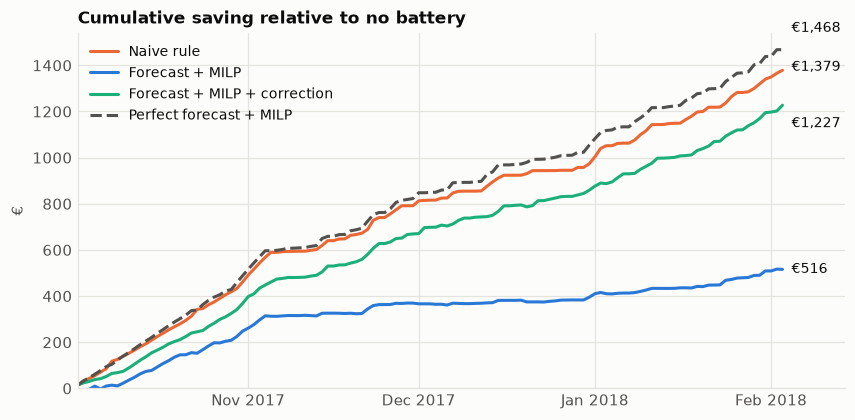

,No battery,Naive rule,Forecast + MILP,Forecast + MILP + correction,Perfect forecast + MILP
day,,,,,
2017-10,420.0,-40.0,172.0,52.0,-67.0
2017-11,1633.0,1302.0,1511.0,1331.0,1298.0
2017-12,2091.0,1909.0,2065.0,1901.0,1860.0
2018-01,1743.0,1377.0,1629.0,1407.0,1359.0
2018-02,182.0,144.0,175.0,150.0,153.0


In [4]:
saving = daily[with_battery].rsub(daily["no_battery"], axis=0).cumsum()
fig, ax = plt.subplots(figsize=(9, 4.2))
offsets = {"perfect": 14, "rule": 2, "milp_corrected": -12, "milp": 0}
for name in with_battery:
    ax.plot(saving.index, saving[name], label=STRATEGIES[name], **STRATEGY_STYLES[name])
    ax.annotate(f"€{saving[name].iloc[-1]:,.0f}", (saving.index[-1], saving[name].iloc[-1]),
                xytext=(6, offsets[name]), textcoords="offset points", va="center", fontsize=9)
ax.set_xlim(saving.index[0], saving.index[-1] + pd.Timedelta(days=11))
ax.set_ylim(0, None)
ax.set_ylabel("€")
ax.set_title("Cumulative saving relative to no battery")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper left", fontsize=9)
plt.show()

monthly = daily[list(STRATEGIES)].groupby(daily.index.to_period("M")).sum()
monthly.columns = [STRATEGIES[name] for name in monthly.columns]
monthly.round(0)

**What we see**

- The saving builds up in October, November and January. In December, with little PV, every strategy saves little (€182 for the naive rule): the battery has little to store.
- The plan executed to the letter falls behind from the first week and never catches up.
- The naive rule and the plan with correction move almost together. In December the plan with correction is slightly ahead (€1,901 against €1,909); in the sunnier months the naive rule prevails.
- The plan with correction costs less than the naive rule on 58 days out of 125.

## 3. What the forecast error costs

The extra cost of a day is the difference between *Forecast + MILP* and *Perfect forecast + MILP*. Both strategies close every day with the battery at the same level, so the days can be compared one by one.

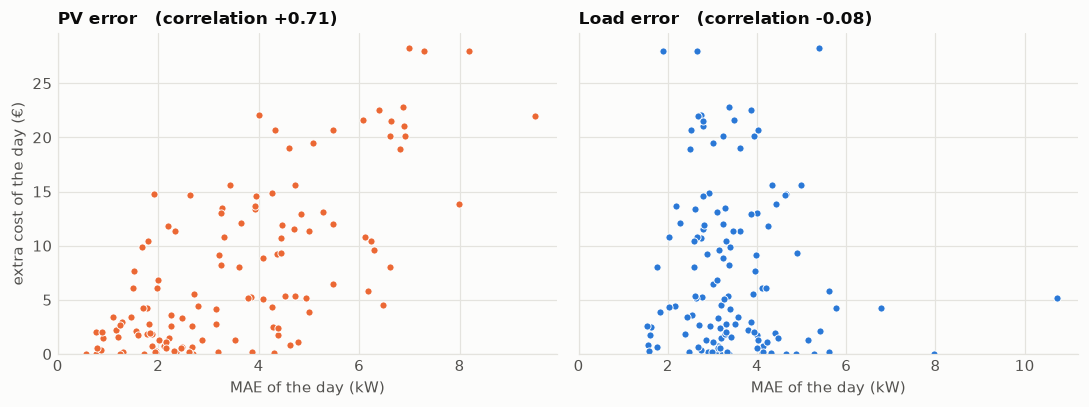

Total extra cost: €952   mean €7.62/day   median 5.18   max 28.21
The 25 worst days (20%) make up 52% of the total


,forecast + MILP (€),perfect + MILP (€),extra cost (€),load MAE (kW),PV MAE (kW),load error (kWh),PV error (kWh)
2017-12-13,36.6,8.4,28.2,5.4,7.0,99.6,-138.1
2017-12-01,64.7,36.8,28.0,2.6,7.3,-3.7,-131.0
2017-10-06,25.9,-2.0,28.0,1.9,8.2,-2.6,132.6
2017-12-07,33.5,10.6,22.8,3.4,6.9,25.1,-157.1
2017-11-27,42.3,19.8,22.5,3.9,6.4,-11.2,-103.3


In [5]:
extra = (daily["milp"] - daily["perfect"]).rename("extra cost (€)")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
panels = [("pv_mae_kw", "pv", "PV error"), ("load_mae_kw", "load", "Load error")]
for ax, (column, color, title) in zip(axes, panels):
    ax.scatter(daily[column], extra, s=22, color=COLORS[color], edgecolor="white", linewidth=0.6)
    ax.set_xlabel("MAE of the day (kW)")
    ax.set_xlim(0, None)
    ax.set_title(f"{title}   (correlation {extra.corr(daily[column]):+.2f})")
axes[0].set_ylabel("extra cost of the day (€)")
axes[0].set_ylim(0, None)
fig.tight_layout()
plt.show()

print(f"Total extra cost: €{extra.sum():.0f}   mean €{extra.mean():.2f}/day   median {extra.median():.2f}   max {extra.max():.2f}")
print(f"The 25 worst days (20%) make up {extra.nlargest(25).sum() / extra.sum():.0%} of the total")
worst = daily.loc[extra.nlargest(5).index, ["milp", "perfect", "load_mae_kw", "pv_mae_kw", "load_error_kwh", "pv_error_kwh"]]
worst.insert(2, "extra cost (€)", extra)
worst.index = worst.index.date
worst.rename(columns={"milp": "forecast + MILP (€)", "perfect": "perfect + MILP (€)", "load_mae_kw": "load MAE (kW)",
                      "pv_mae_kw": "PV MAE (kW)", "load_error_kwh": "load error (kWh)",
                      "pv_error_kwh": "PV error (kWh)"}).round(1)

**What we see**

- The forecast error costs €952 over 125 days: €7.6 a day on average, never below zero, €28 at most.
- **It is the PV error that matters, not the load error.** The extra cost grows with the PV error (correlation +0.71: about €2.7 for every kW of MAE) and does not depend on the load error (−0.08). PV has much larger errors in energy terms: over 100 kWh on the worst days.
- There are no catastrophic days: the 25 worst days make up about half of the total. The loss is spread out, not concentrated.
- On the worst days the error goes both ways: sun that was forecast and did not come (6 October: the battery charges from the grid) or sun that came unannounced (1, 7 and 13 December: the unplanned surplus is sold cheaply).
- A better load forecast would not help at all; a better PV forecast would, and here it is already optimistic because it uses observed weather.

## 4. Cost–emissions Pareto front

The simulation is repeated with increasing weights `λ` on emissions. Every panel spans the same range (400 kgCO₂ and €120), so the three curves can be compared.

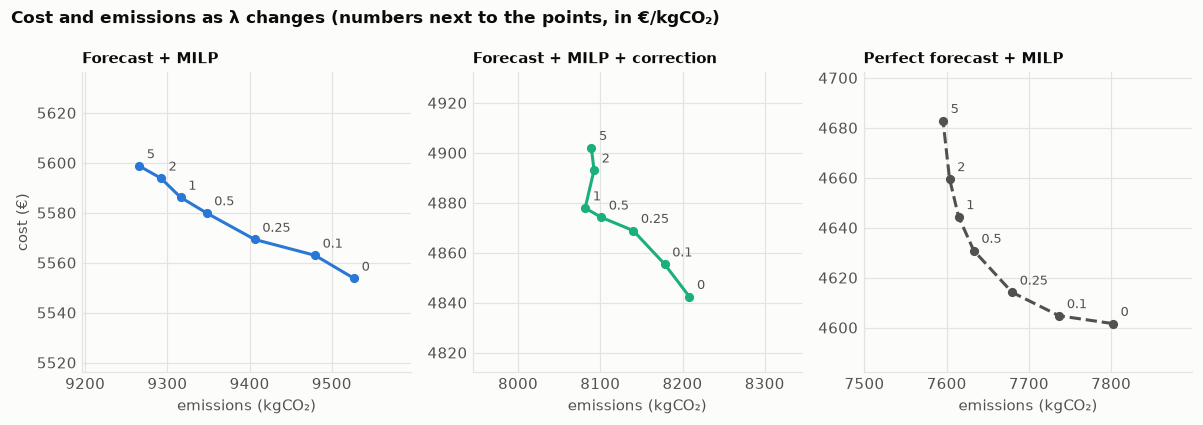

cost_eur                        emissions_kg  \
strategy                 milp milp_corrected perfect         milp   
carbon_weight_eur_kg                                                
0.00                   5554.0         4842.0  4602.0       9527.0   
0.10                   5563.0         4855.0  4605.0       9480.0   
0.25                   5569.0         4869.0  4614.0       9406.0   
0.50                   5580.0         4874.0  4631.0       9348.0   
1.00                   5586.0         4878.0  4644.0       9316.0   
2.00                   5594.0         4893.0  4660.0       9292.0   
5.00                   5599.0         4902.0  4683.0       9266.0   

                                             
strategy             milp_corrected perfect  
carbon_weight_eur_kg                         
0.00                         8208.0  7802.0  
0.10                         8178.0  7737.0  
0.25                         8140.0  7680.0  
0.50                         8101.0  7633.0  
1.00                         8082.0  7614.0  
2.00                         8092.0  7603.0  
5.00                         8089.0  7596.0

In [6]:
plot_pareto(front, STRATEGIES)
plt.show()

pivot = front.pivot(index="carbon_weight_eur_kg", columns="strategy", values=["cost_eur", "emissions_kg"])
pivot.round(0)

**What we see**

- **The trade-off exists but is small.** With a perfect forecast, going from `λ` = 0 to `λ` = 5 €/kgCO₂ cuts emissions by 2.6% (from 7,802 to 7,596 kg) and raises cost by 1.8% (from €4,602 to €4,683).
- Most of the gain comes early: at `λ` = 1 we are already at 7,614 kg for €43 more, i.e. about €230 per tonne of CO₂ avoided. Beyond that the curve is almost vertical.
- With the real forecasts the shape is the same, shifted towards higher cost and emissions. With the correction the curve is not monotonic: beyond `λ` = 1 emissions creep back up, because the battery no longer follows the plan exactly.
- The reason is the same as in section 1: emissions depend mostly on how much energy is bought, not on when. Moving purchases to the clean hours shifts little.

## 5. Sensitivity analysis

One parameter changes at a time; the others stay at their defaults (200 kWh and 50 kW battery, 100 kWp of PV, 0.20 €/kWh surcharge). The battery power does not change with capacity.

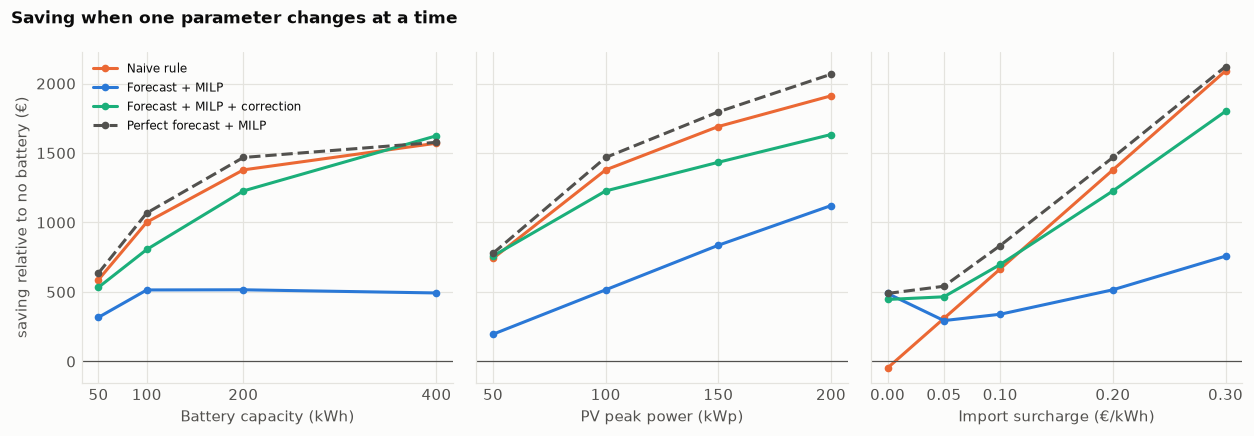

strategy                         Naive rule  Forecast + MILP  \
parameter                value                                 
battery_capacity_kwh     50.00        588.0            318.0   
                         100.00      1002.0            515.0   
                         200.00      1379.0            516.0   
                         400.00      1571.0            493.0   
import_surcharge_eur_kwh 0.00         -47.0            489.0   
                         0.05         310.0            294.0   
                         0.10         666.0            340.0   
                         0.20        1379.0            516.0   
                         0.30        2091.0            758.0   
pv_peak_kw               50.00        742.0            196.0   
                         100.00      1379.0            516.0   
                         150.00      1691.0            836.0   
                         200.00      1911.0           1122.0   

strategy                         Forecast + MILP + correction  \
parameter                value                                  
battery_capacity_kwh     50.00                          534.0   
                         100.00                         806.0   
                         200.00                        1227.0   
                         400.00                        1624.0   
import_surcharge_eur_kwh 0.00                           446.0   
                         0.05                           465.0   
                         0.10                           698.0   
                         0.20                          1227.0   
                         0.30                          1800.0   
pv_peak_kw               50.00                          759.0   
                         100.00                        1227.0   
                         150.00                        1433.0   
                         200.00                        1633.0   

strategy                         Perfect forecast + MILP  
parameter                value                            
battery_capacity_kwh     50.00                     636.0  
                         100.00                   1068.0  
                         200.00                   1468.0  
                         400.00                   1577.0  
import_surcharge_eur_kwh 0.00                      489.0  
                         0.05                      541.0  
                         0.10                      834.0  
                         0.20                     1468.0  
                         0.30                     2122.0  
pv_peak_kw               50.00                     779.0  
                         100.00                   1468.0  
                         150.00                   1796.0  
                         200.00                   2067.0

In [7]:
plot_sensitivity(sweep, STRATEGIES)
plt.show()

view = sweep[sweep["strategy"] != "no_battery"].pivot(index=["parameter", "value"], columns="strategy", values="cost_saving_eur")
view[with_battery].rename(columns=STRATEGIES).round(0)

**What we see**

- **Battery capacity.** The saving grows with capacity but less and less: from 100 to 200 kWh the naive rule gains €377, from 200 to 400 kWh only €192. The plan executed to the letter stays at about €500 whatever the capacity: more battery means more energy moved on the basis of wrong forecasts.
- **PV peak power.** The more sun there is, the more the battery is worth, for every strategy. At 50 kWp the plan with correction edges past the naive rule (€759 against €742).
- **Import surcharge: this is the parameter that decides who wins.**
  - With no surcharge only price arbitrage matters: the MILP nearly wipes out the cost (from €496 to €7), while the naive rule **loses** €47 compared with having no battery. But the MILP's emissions double (19,509 kg against 10,496), because it buys and resells grid energy.
  - At 0.05 €/kWh the plan with correction saves €465, the naive rule €310.
  - At 0.10 €/kWh they are level (€698 against €666).
  - From 0.20 €/kWh up the naive rule wins.
- **The perfect forecast is not an absolute upper bound.** At 400 kWh the naive rule and the plan with correction match or beat it. The MILP plans one day at a time and must close every day at its starting level; the other two strategies can carry energy from one day to the next and end the period with an emptier battery.

## Conclusions

- **Answer to the project's question.** With the reference tariff, forecast + optimisation does **not** save money compared with a simple rule: 20.2% against 22.7% at best, 8.5% when the plan is executed to the letter. It saves compared with having no battery; compared with the naive rule it does not.
- **Why.** With a 0.20 €/kWh import surcharge, a self-consumed kWh is worth about seven times the typical price difference between the hours of a day. The goal becomes maximising self-consumption, and for that it is enough to react to the actual surplus: there is no need to forecast it. The gap between the naive rule and the perfect forecast is under 2% of the cost.
- **When optimisation helps.** With a low surcharge (up to 0.10 €/kWh) the value lies in price arbitrage, which the naive rule cannot see: there the MILP wins, and with no surcharge it is the only strategy that makes money.
- **How the plan is executed matters more than how it is computed.** Letting the battery absorb the forecast error instead of the grid is worth €711: three quarters of what a perfect forecast would give (€952).
- **The error that costs money is the PV one**, not the load one.
- **Emissions.** Weighting emissions in the objective cuts them by 2–3% at most: they depend on how much energy is bought, not on when.

Limits of these results: the test set covers autumn and winter only; the weather used to forecast PV is the observed one; the tariff is a simplification; the correction rule was chosen on validation, but the final comparison is on a single period of 125 days.